# Digital Product Analytics — Exploratory Analysis
### Onboarding funnel conversion, device friction, and telemetry errors

**Dataset:** `data/raw_sample_data.csv` — 1,000 telemetry events, 290 onboarding sessions, 1–14 Sep 2026
**Questions this notebook answers**

1. Where does the onboarding funnel lose sessions, stage by stage?
2. Is the loss a product problem or a device problem?
3. What exactly is `ERR_MOBILE_RENDER_502`, how many conversions does it cost, and what is fixing it worth?
4. Do user segments behave differently?

**Method rule:** every KPI is counted in **unique sessions**, never raw events. Event counts are telemetry volume only.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
from pathlib import Path


def locate(relative):
    """Resolve a repo-relative path whether the kernel starts at the repo root,
    inside python/, or in any parent of either."""
    cwd = Path.cwd().resolve()
    here = Path(globals().get("__file__", ".")).resolve()
    for root in [cwd, *cwd.parents, here, *here.parents]:
        if (root / relative).exists():
            return root / relative
    raise FileNotFoundError(relative)


df = pd.read_csv(locate("data/raw_sample_data.csv"), parse_dates=["event_timestamp"])
df.head()

,event_id,session_id,user_id,event_timestamp,event_type,page_url,device_type,user_segment,error_code,duration_sec
0,EVT-0001,SES-0001,USR-0001,2026-09-01 08:04:45,page_view,/landing,Desktop,Enterprise,NaN,12.10
1,EVT-0002,SES-0001,USR-0001,2026-09-01 08:05:08,signup_started,/onboarding-1,Desktop,Enterprise,NaN,35.90
2,EVT-0003,SES-0001,USR-0001,2026-09-01 08:06:08,form_step_1_completed,/onboarding-2,Desktop,Enterprise,NaN,95.90
3,EVT-0004,SES-0001,USR-0001,2026-09-01 08:07:06,onboarding_completed,/dashboard,Desktop,Enterprise,NaN,153.00
4,EVT-0005,SES-0002,USR-0002,2026-09-01 08:35:52,page_view,/landing,Desktop,Free,NaN,18.00


In [3]:
print("events:", len(df))
print("sessions:", df["session_id"].nunique())
print("users:", df["user_id"].nunique())
df.shape

events: 1000
sessions: 290
users: 290


(1000, 10)

In [4]:
df.dtypes

event_id                      str
session_id                    str
user_id                       str
event_timestamp    datetime64[us]
event_type                    str
page_url                      str
device_type                   str
user_segment                  str
error_code                    str
duration_sec              float64
dtype: object

In [5]:
df.isna().sum()

event_id             0
session_id           0
user_id              0
event_timestamp      0
event_type           0
page_url             0
device_type          0
user_segment         0
error_code         972
duration_sec         0
dtype: int64

`error_code` shows as missing/empty on normal events — that is expected, it is only populated on error events.
Empty strings read from the CSV are handled in Step 3.

## 2. Quick data-quality checks

In [6]:
print("duplicate event_id:", df["event_id"].duplicated().sum())
print("null session_id:", df["session_id"].isna().sum())
print("null event_timestamp:", df["event_timestamp"].isna().sum())

duplicate event_id: 0
null session_id: 0
null event_timestamp: 0


In [7]:
df["device_type"].value_counts()

device_type
Desktop    525
Mobile     306
Tablet     169
Name: count, dtype: int64

In [8]:
df["user_segment"].value_counts()

user_segment
Free          559
Premium       263
Enterprise    178
Name: count, dtype: int64

In [9]:
df["event_type"].value_counts()

event_type
page_view                290
signup_started           241
form_step_1_completed    201
onboarding_completed     167
button_click              73
error                     28
Name: count, dtype: int64

In [10]:
df["error_code"].value_counts(dropna=False)

error_code
NaN                      972
ERR_MOBILE_RENDER_502     28
Name: count, dtype: int64

In [11]:
# error events only
err = df[df["error_code"] == "ERR_MOBILE_RENDER_502"]
print("error events:", len(err))
print("error sessions:", err["session_id"].nunique())
err.head()

error events: 28
error sessions: 28


,event_id,session_id,user_id,event_timestamp,event_type,page_url,device_type,user_segment,error_code,duration_sec
89,EVT-0090,SES-0023,USR-0023,2026-09-02 09:40:50,error,/onboarding-1,Mobile,Free,ERR_MOBILE_RENDER_502,42.20
171,EVT-0172,SES-0046,USR-0046,2026-09-03 10:05:11,error,/onboarding-1,Mobile,Premium,ERR_MOBILE_RENDER_502,30.60
176,EVT-0177,SES-0048,USR-0048,2026-09-03 11:09:55,error,/onboarding-1,Mobile,Free,ERR_MOBILE_RENDER_502,26.20
180,EVT-0181,SES-0050,USR-0050,2026-09-03 13:44:06,error,/onboarding-1,Mobile,Free,ERR_MOBILE_RENDER_502,44.70
243,EVT-0244,SES-0070,USR-0070,2026-09-04 16:55:08,error,/onboarding-1,Mobile,Free,ERR_MOBILE_RENDER_502,34.10


The full rule-by-rule validation (funnel order, no stage skips, device/segment stability inside a session,
timestamp ordering) lives in `data_quality_checks.py` — **23/23 checks pass** on this file.

## 3. Build the session-level table
Funnel questions are session questions, so collapse events to **one row per session** first.
All later tables are simple group-bys on this frame.

In [12]:
session_level = df.groupby("session_id").agg(
    user_id=("user_id", "first"),
    device_type=("device_type", "first"),
    user_segment=("user_segment", "first"),
    session_start=("event_timestamp", "min"),
    event_count=("event_id", "count"),
    session_duration_sec=("duration_sec", "max"),
).reset_index()
session_level.head()

,session_id,user_id,device_type,user_segment,session_start,event_count,session_duration_sec
0,SES-0001,USR-0001,Desktop,Enterprise,2026-09-01 08:04:45,4,153.00
1,SES-0002,USR-0002,Desktop,Free,2026-09-01 08:35:52,5,152.90
2,SES-0003,USR-0003,Mobile,Free,2026-09-01 09:00:43,3,87.90
3,SES-0004,USR-0004,Tablet,Free,2026-09-01 09:10:43,2,30.90
4,SES-0005,USR-0005,Desktop,Free,2026-09-01 09:19:57,3,76.20


In [13]:
# one flag per funnel stage: did this session reach the stage at all?
FUNNEL = ["page_view", "signup_started", "form_step_1_completed", "onboarding_completed"]
for event in FUNNEL:
    ids = set(df.loc[df["event_type"] == event, "session_id"])
    session_level["reached_" + event] = session_level["session_id"].isin(ids).astype(int)
session_level.head()

,session_id,user_id,device_type,user_segment,session_start,event_count,session_duration_sec,reached_page_view,reached_signup_started,reached_form_step_1_completed,reached_onboarding_completed
0,SES-0001,USR-0001,Desktop,Enterprise,2026-09-01 08:04:45,4,153.00,1,1,1,1
1,SES-0002,USR-0002,Desktop,Free,2026-09-01 08:35:52,5,152.90,1,1,1,1
2,SES-0003,USR-0003,Mobile,Free,2026-09-01 09:00:43,3,87.90,1,1,1,0
3,SES-0004,USR-0004,Tablet,Free,2026-09-01 09:10:43,2,30.90,1,1,0,0
4,SES-0005,USR-0005,Desktop,Free,2026-09-01 09:19:57,3,76.20,1,1,1,0


In [14]:
session_level["is_converted"] = session_level["reached_onboarding_completed"]

In [15]:
error_ids = set(err["session_id"])
session_level["has_render_error"] = session_level["session_id"].isin(error_ids).astype(int)
session_level.head()

,session_id,user_id,device_type,user_segment,session_start,event_count,session_duration_sec,reached_page_view,reached_signup_started,reached_form_step_1_completed,reached_onboarding_completed,is_converted,has_render_error
0,SES-0001,USR-0001,Desktop,Enterprise,2026-09-01 08:04:45,4,153.00,1,1,1,1,1,0
1,SES-0002,USR-0002,Desktop,Free,2026-09-01 08:35:52,5,152.90,1,1,1,1,1,0
2,SES-0003,USR-0003,Mobile,Free,2026-09-01 09:00:43,3,87.90,1,1,1,0,0,0
3,SES-0004,USR-0004,Tablet,Free,2026-09-01 09:10:43,2,30.90,1,1,0,0,0,0
4,SES-0005,USR-0005,Desktop,Free,2026-09-01 09:19:57,3,76.20,1,1,1,0,0,0


In [16]:
session_level["session_date"] = session_level["session_start"].dt.date

## 4. Executive KPI summary

In [17]:
total_sessions = len(session_level)
total_users = session_level["user_id"].nunique()
conversions = int(session_level["is_converted"].sum())
conversion_rate = conversions / total_sessions * 100
print("total sessions:", total_sessions)
print("total users:", total_users)
print("conversions:", conversions)
print("overall conversion rate: %.2f%%" % conversion_rate)

total sessions: 290
total users: 290
conversions: 167
overall conversion rate: 57.59%


In [18]:
kpi_summary = pd.DataFrame({
    "kpi": ["Total events", "Total sessions", "Total users", "Conversions", "Overall conversion rate %"],
    "value": [len(df), total_sessions, total_users, conversions, round(conversion_rate, 2)],
})
kpi_summary

,kpi,value
0,Total events,1000.00
1,Total sessions,290.00
2,Total users,290.00
3,Conversions,167.00
4,Overall conversion rate %,57.59


## 5. Funnel analysis — stage by stage

In [19]:
funnel = pd.DataFrame({
    "funnel_stage": ["1. Page View", "2. Signup Started", "3. Form Step 1 Completed", "4. Onboarding Completed"],
    "page_url": ["/landing", "/onboarding-1", "/onboarding-2", "/dashboard"],
    "sessions": [int(session_level["reached_" + e].sum()) for e in FUNNEL],
})
funnel

,funnel_stage,page_url,sessions
0,1. Page View,/landing,290
1,2. Signup Started,/onboarding-1,241
2,3. Form Step 1 Completed,/onboarding-2,201
3,4. Onboarding Completed,/dashboard,167


In [20]:
funnel["stage_retention_pct"] = funnel["sessions"] / funnel["sessions"].shift(1) * 100
funnel["stage_retention_pct"] = funnel["stage_retention_pct"].fillna(100.0)
funnel["cumulative_retention_pct"] = funnel["sessions"] / funnel["sessions"].iloc[0] * 100
funnel["sessions_lost_at_stage"] = funnel["sessions"].shift(1) - funnel["sessions"]
funnel

,funnel_stage,page_url,sessions,stage_retention_pct,cumulative_retention_pct,sessions_lost_at_stage
0,1. Page View,/landing,290,100.00,100.00,NaN
1,2. Signup Started,/onboarding-1,241,83.10,83.10,49.00
2,3. Form Step 1 Completed,/onboarding-2,201,83.40,69.31,40.00
3,4. Onboarding Completed,/dashboard,167,83.08,57.59,34.00


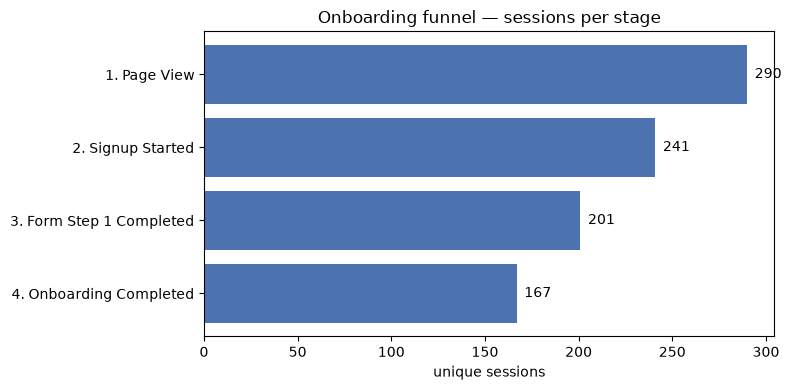

In [21]:
plt.figure(figsize=(8, 4))
plt.barh(funnel["funnel_stage"][::-1], funnel["sessions"][::-1], color="#4C72B0")
for i, v in enumerate(funnel["sessions"][::-1]):
    plt.text(v + 4, i, str(v), va="center")
plt.xlabel("unique sessions")
plt.title("Onboarding funnel — sessions per stage")
plt.tight_layout()
plt.show()

**Read:** each individual stage retains ~83% — no single stage is broken on its own.
The loss is spread evenly, which points away from form design at one step and towards
a *population* that struggles everywhere. That population shows up in the device split.

## 6. Device breakdown — where the gap actually is

In [22]:
device_funnel = session_level.groupby("device_type")[
    ["reached_" + e for e in FUNNEL]].sum()
device_funnel

,reached_page_view,reached_signup_started,reached_form_step_1_completed,reached_onboarding_completed
device_type,,,,
Desktop,142,134,114,101
Mobile,98,61,50,36
Tablet,50,46,37,30


In [23]:
device = session_level.groupby("device_type").agg(
    total_sessions=("session_id", "count"),
    conversions=("is_converted", "sum"),
    error_sessions=("has_render_error", "sum"),
).reset_index()
device["conversion_rate_pct"] = device["conversions"] / device["total_sessions"] * 100
device["total_drop_offs"] = device["total_sessions"] - device["conversions"]
device["error_rate_pct"] = device["error_sessions"] / device["total_sessions"] * 100
device

,device_type,total_sessions,conversions,error_sessions,conversion_rate_pct,total_drop_offs,error_rate_pct
0,Desktop,142,101,0,71.13,41,0.00
1,Mobile,98,36,28,36.73,62,28.57
2,Tablet,50,30,0,60.00,20,0.00


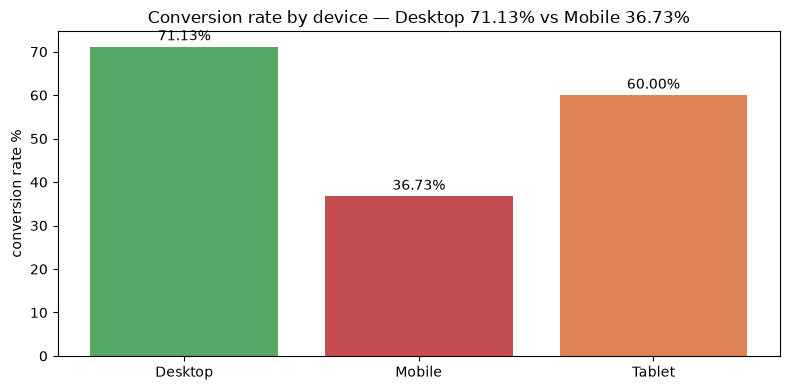

In [24]:
plt.figure(figsize=(8, 4))
colors = ["#55A868" if d == "Desktop" else "#C44E52" if d == "Mobile" else "#DD8452"
          for d in device["device_type"]]
plt.bar(device["device_type"], device["conversion_rate_pct"], color=colors)
for i, v in enumerate(device["conversion_rate_pct"]):
    plt.text(i, v + 1.5, "%.2f%%" % v, ha="center")
plt.ylabel("conversion rate %")
plt.title("Conversion rate by device — Desktop 71.13% vs Mobile 36.73%")
plt.tight_layout()
plt.show()

**Read:** Desktop converts at **71.13%**, Tablet at **60.00%**, Mobile at **36.73%** —
a 34.4-point platform gap. Mobile also drops hardest at the very first transition
(98 views → 61 signups, 62.2% stage retention vs 94.4% on Desktop).
A first-step, mobile-only collapse is the signature of a technical failure, not a UX preference.

## 7. Root cause — ERR_MOBILE_RENDER_502

In [25]:
error_by_device = session_level.groupby("device_type")["has_render_error"].agg(["sum", "count"])
error_by_device.columns = ["error_sessions", "total_sessions"]
error_by_device["error_rate_pct"] = error_by_device["error_sessions"] / error_by_device["total_sessions"] * 100
error_by_device

,error_sessions,total_sessions,error_rate_pct
device_type,,,
Desktop,0,142,0.00
Mobile,28,98,28.57
Tablet,0,50,0.00


In [26]:
mobile = session_level[session_level["device_type"] == "Mobile"]
mobile_stage1_drops = int((mobile["reached_page_view"] - mobile["reached_signup_started"]).sum())
mobile_drops_total = int(len(mobile) - mobile["is_converted"].sum())
print("mobile sessions:", len(mobile))
print("mobile drop-offs at stage 1 (landing -> signup):", mobile_stage1_drops)
print("mobile total drop-offs:", mobile_drops_total)
print("error sessions:", int(mobile["has_render_error"].sum()))
print("errors as share of stage-1 drop-offs: %.2f%%" % (mobile["has_render_error"].sum() / mobile_stage1_drops * 100))
print("errors as share of all mobile drop-offs: %.2f%%" % (mobile["has_render_error"].sum() / mobile_drops_total * 100))

mobile sessions: 98
mobile drop-offs at stage 1 (landing -> signup): 37
mobile total drop-offs: 62
error sessions: 28
errors as share of stage-1 drop-offs: 75.68%
errors as share of all mobile drop-offs: 45.16%


In [27]:
impact = mobile.groupby("has_render_error").agg(
    sessions=("session_id", "count"), conversions=("is_converted", "sum")).reset_index()
impact["conversion_rate_pct"] = impact["conversions"] / impact["sessions"] * 100
impact["cohort"] = np.where(impact["has_render_error"] == 1,
                            "With ERR_MOBILE_RENDER_502", "Without error")
impact[["cohort", "sessions", "conversions", "conversion_rate_pct"]]

,cohort,sessions,conversions,conversion_rate_pct
0,Without error,70,36,51.43
1,With ERR_MOBILE_RENDER_502,28,0,0.00


Every one of the 28 error sessions drops before `signup_started`, and **no error session converts**.
Mobile sessions without the error convert at 51.43% — the error is the difference between a mediocre
mobile funnel and a broken one.

## 8. What is fixing the bug worth? (counterfactual)

In [28]:
no_error_rate = impact.loc[impact["has_render_error"] == 0, "conversion_rate_pct"].iloc[0] / 100
error_sessions = int(mobile["has_render_error"].sum())
mobile_conv = int(mobile["is_converted"].sum())

realistic_extra = error_sessions * no_error_rate
realistic_rate = (mobile_conv + realistic_extra) / len(mobile) * 100
upper_extra = error_sessions
upper_rate = (mobile_conv + upper_extra) / len(mobile) * 100

print("mobile today:            %d/%d = %.2f%%" % (mobile_conv, len(mobile), mobile_conv / len(mobile) * 100))
print("realistic fix scenario:  +%.1f conversions -> %.2f%% (error sessions convert at the no-error mobile rate)"
      % (realistic_extra, realistic_rate))
print("upper-bound scenario:    +%d conversions -> %.2f%% (every error session converts)"
      % (upper_extra, upper_rate))

mobile today:            36/98 = 36.73%
realistic fix scenario:  +14.4 conversions -> 51.43% (error sessions convert at the no-error mobile rate)
upper-bound scenario:    +28 conversions -> 65.31% (every error session converts)


**Read:** quote the **realistic** number (~51.4% mobile conversion, ~14 extra conversions per 98 mobile
sessions) in planning. 65.31% is an upper bound — it assumes a 100% save rate on error sessions.

## 9. User segments

In [29]:
segment = session_level.groupby("user_segment").agg(
    total_sessions=("session_id", "count"),
    conversions=("is_converted", "sum"),
    error_sessions=("has_render_error", "sum"),
    avg_session_duration_sec=("session_duration_sec", "mean"),
).reset_index()
segment["conversion_rate_pct"] = segment["conversions"] / segment["total_sessions"] * 100
segment = segment.round(2)
segment

,user_segment,total_sessions,conversions,error_sessions,avg_session_duration_sec,conversion_rate_pct
0,Enterprise,50,30,4,106.77,60.00
1,Free,166,89,17,97.29,53.61
2,Premium,74,48,7,105.49,64.86


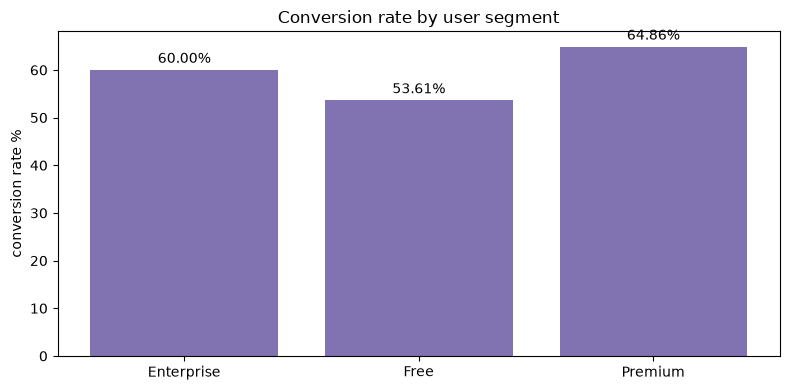

In [30]:
plt.figure(figsize=(8, 4))
plt.bar(segment["user_segment"], segment["conversion_rate_pct"], color="#8172B2")
for i, v in enumerate(segment["conversion_rate_pct"]):
    plt.text(i, v + 1.5, "%.2f%%" % v, ha="center")
plt.ylabel("conversion rate %")
plt.title("Conversion rate by user segment")
plt.tight_layout()
plt.show()

**Read:** segments sit within ~11 points of each other (Premium 64.86%, Enterprise 60.00%, Free 53.61%),
and the render error hits all three (Free 17, Premium 7, Enterprise 4 error sessions).
Segment is a secondary effect; **device is the story**. Free users carry the largest error count
simply because they are the largest segment (166 of 290 sessions).

## 10. Time in funnel

In [31]:
duration_stats = (df[df["event_type"].isin(FUNNEL)]
                    .groupby("event_type")["duration_sec"]
                    .agg(["count", "mean", "median", "std"])
                    .reindex(FUNNEL).round(1))
duration_stats

,count,mean,median,std
event_type,,,,
page_view,290,11.60,11.60,4.20
signup_started,241,37.60,37.80,7.30
form_step_1_completed,201,80.80,81.60,10.80
onboarding_completed,167,141.80,143.10,21.60


In [32]:
print("mean elapsed time when the mobile render error fires: %.1f sec"
      % err["duration_sec"].mean())
err["duration_sec"].describe()

mean elapsed time when the mobile render error fires: 37.8 sec


count   28.00
mean    37.84
std      4.81
min     26.20
25%     34.98
50%     36.80
75%     40.80
max     48.60
Name: duration_sec, dtype: float64

**Read:** the error fires at ~37 seconds in — exactly when `signup_started` should happen
(stage mean 37.6s). The rendering failure sits on the signup render path on mobile, not on the landing page.

## 11. Daily trend (1–14 Sep 2026)

In [33]:
daily = session_level.groupby("session_date").agg(
    sessions=("session_id", "count"), conversions=("is_converted", "sum")).reset_index()
daily["conversion_rate_pct"] = daily["conversions"] / daily["sessions"] * 100

mobile_daily = mobile.groupby("session_date").agg(
    mobile_sessions=("session_id", "count"), error_sessions=("has_render_error", "sum")).reset_index()
daily = daily.merge(mobile_daily, on="session_date", how="left")
daily["mobile_error_rate_pct"] = daily["error_sessions"] / daily["mobile_sessions"] * 100
daily.round(2)

,session_date,sessions,conversions,conversion_rate_pct,mobile_sessions,error_sessions,mobile_error_rate_pct
0,2026-09-01,22,17,77.27,4,0,0.00
1,2026-09-02,22,14,63.64,6,1,16.67
2,2026-09-03,17,6,35.29,6,3,50.00
3,2026-09-04,16,7,43.75,7,3,42.86
4,2026-09-05,14,9,64.29,5,1,20.00
5,2026-09-06,19,12,63.16,8,2,25.00
6,2026-09-07,23,14,60.87,9,4,44.44
7,2026-09-08,32,17,53.12,12,1,8.33
8,2026-09-09,19,6,31.58,6,3,50.00
9,2026-09-10,18,16,88.89,7,1,14.29


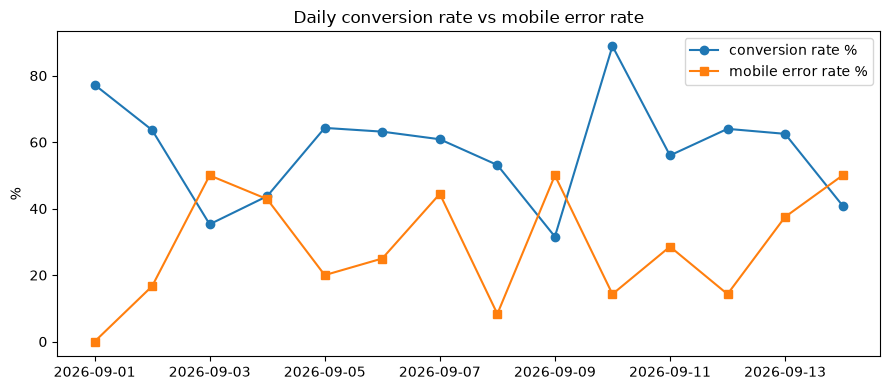

In [34]:
plt.figure(figsize=(9, 4))
plt.plot(daily["session_date"], daily["conversion_rate_pct"], marker="o", label="conversion rate %")
plt.plot(daily["session_date"], daily["mobile_error_rate_pct"], marker="s", label="mobile error rate %")
plt.ylabel("%")
plt.title("Daily conversion rate vs mobile error rate")
plt.legend()
plt.tight_layout()
plt.show()

**Read:** with only ~21 sessions a day, daily rates are noisy — read the *pattern*, not single days.
The error is present across the whole window (it is not a one-day outage), and high-error days
track with the weakest overall conversion days.

## 12. Key insights and recommendations

1. **The funnel is not broken at one stage — Mobile is.** Each stage retains ~83% overall,
   but Mobile converts at 36.73% against Desktop's 71.13%.
2. **Root cause is a rendering bug, not behaviour.** `ERR_MOBILE_RENDER_502` fires on Mobile only,
   on `/onboarding-1` only, at the signup moment (~37s in), in 28.57% of mobile sessions.
   All 28 affected sessions drop out; none convert.
3. **Fix value (per 98 mobile sessions):** realistic ≈ +14 conversions, lifting mobile conversion
   to ~51.4%; absolute upper bound 65.31%.
4. **Segments are secondary.** Premium converts best (64.86%), Free worst (53.61%), but the error
   cuts across every segment — fix the platform issue before segment-level optimisation.
5. **Recommendations**
   - Treat `ERR_MOBILE_RENDER_502` as a P1: reproduce on the mobile signup render path, fix, and
     re-measure the landing → signup transition (target: stage retention from 62.2% towards Desktop's 94.4%).
   - Add an alert on mobile error rate (this sample sits at 28.57% of mobile sessions — any week
     above ~5% should page the team).
   - Keep counting KPIs in unique sessions; raw event volume (1,000) overstates the funnel by design.

## 13. Tableau handoff

The reporting layers in `../sql/02_kpi_modeling.sql` (`session_level`, `kpi_funnel_stage`,
`kpi_device_funnel`, `kpi_device_performance`, `kpi_segment_performance`, `kpi_error_impact`,
`kpi_daily_trend`) are the exact tables this notebook computes in pandas — connect Tableau to
those views so the dashboard and this analysis can never disagree. Workbook specification is in
`../dashboards/README.md`.